In [ ]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

DATA_DIR = Path("data")
VECTOR_FIELDS = {"velocity", "meanvelocity", "force"}
VECTOR_LABELS = {
    "velocity": ["u", "v", "w"],
    "meanvelocity": ["mean u", "mean v", "mean w"],
    "force": ["Fx", "Fy", "Fz"],
}
TENSOR_LABELS = ["xx", "yy", "zz", "xy", "xz", "yz"]


def load_field(path):
    with h5py.File(path, "r") as data_file:
        dataset_name = next(
            name
            for name in data_file
            if name not in {"xcoor", "ycoor", "zcoor", "values"}
        )
        field = np.asarray(data_file[dataset_name])
        coordinates = tuple(
            np.asarray(data_file[name]) for name in ("xcoor", "ycoor", "zcoor")
        )
    return dataset_name.removesuffix("_0001"), field, coordinates


fields = {}
for path in sorted(DATA_DIR.glob("*.h5")):
    name, field, coordinates = load_field(path)
    fields[name] = {"data": field, "coordinates": coordinates, "path": path}

print("Geladene Felder:")
for name, entry in fields.items():
    print(f"  {name}: {entry['data'].shape}")

# Alle vorhandenen Komponenten bzw. Beträge als 2D-Schnitte in mittlerer z-Hoehe.
plot_fields = {}
for name, entry in fields.items():
    field = entry["data"]
    if field.shape[-1] == 3 and name in VECTOR_FIELDS:
        for component, label in enumerate(VECTOR_LABELS[name]):
            plot_fields[f"{name} {label}"] = (
                field[..., component],
                entry["coordinates"],
            )
        plot_fields[f"{name} |v|" if "velocity" in name else f"{name} |F|"] = (
            np.linalg.norm(field, axis=-1),
            entry["coordinates"],
        )
    elif field.shape[-1] == 6:
        for component, label in enumerate(TENSOR_LABELS):
            plot_fields[f"{name} {label}"] = (
                field[..., component],
                entry["coordinates"],
            )
    else:
        plot_fields[name] = (np.squeeze(field, axis=-1), entry["coordinates"])

figure_columns = 4
figure_rows = int(np.ceil(len(plot_fields) / figure_columns))
fig_overview, axes = plt.subplots(
    figure_rows,
    figure_columns,
    figsize=(5 * figure_columns, 4 * figure_rows),
    squeeze=False,
    constrained_layout=True,
)

for axis, (label, (field, coordinates)) in zip(axes.flat, plot_fields.items()):
    x, y, z = coordinates
    z_index = len(z) // 2
    z_index = 18
    image = axis.contourf(x, y, field[z_index], levels=25, cmap="viridis")
    axis.set_title(f"{label}, z = {z[z_index]:.1f}")
    axis.set_xlabel("x")
    axis.set_ylabel("y")
    axis.set_aspect("equal")
    fig_overview.colorbar(image, ax=axis, label=label)

for axis in axes.flat[len(plot_fields) :]:
    axis.set_visible(False)

fig_overview.savefig("all_fields_2d.png", dpi=180)
plt.show()

Geladene Felder:


ValueError: Number of rows must be a positive integer, not 0

<Figure size 2000x0 with 0 Axes>

In [ ]:
# Betrag des vollständigen Geschwindigkeitsvektors |v| = sqrt(u^2 + v^2 + w^2).
speed_xyz = np.transpose(speed, (2, 1, 0))
speed_min, speed_max = np.nanpercentile(speed_xyz, [5, 95])

fig_speed = go.Figure(
    data=go.Isosurface(
        x=X_3d.ravel(),
        y=Y_3d.ravel(),
        z=Z_3d.ravel(),
        value=speed_xyz.ravel(),
        isomin=float(speed_min),
        isomax=float(speed_max),
        colorscale="Viridis",
        opacity=0.55,
        surface_count=8,
        caps=dict(x_show=False, y_show=False, z_show=False),
        colorbar=dict(title="|v| [m/s]"),
    )
)
fig_speed.update_layout(
    title="3D-Isosurface des Betrags des Geschwindigkeitsvektors |v|",
    width=1100,
    height=750,
    margin=dict(l=0, r=0, t=70, b=0),
    scene=dict(
        xaxis_title="x [m]",
        yaxis_title="y [m]",
        zaxis_title="z [m]",
        aspectmode="data",
    ),
)
fig_speed.write_html("velocity_3d_speed_magnitude.html", include_plotlyjs="cdn")
fig_speed.show()

In [ ]:
from pathlib import Path


import h5py
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import StandardScaler
import torch

DATA_DIR = Path("..") / "data"
z_index = 18
train_n = 100
col_n = 100
device = "cpu"

# def get_wake_2d_data(data_dir: str, z_index: int, train_n: int, n_col: int, device: str):
# 1. HDF5 laden & bei z_index schneiden -> X, Y, u_true, v_true, p_true
# 2. Zufällige Indizes für train_batch ziehen (n_data Punkte für Data-Loss, n_col für PDE)
# 3. Gesamtes Gitter in val_batch packen
# 4. true_dict = {"u": u_true, "v": v_true, "p": p_true}


with h5py.File(DATA_DIR / "meanvelocity.h5", "r") as data_file:
    field = np.asarray(
        data_file["meanvelocity_0001"]
    )  # z,y,x, (u, v, w) (25, 30, 301, 3)
    coordinates = tuple(
        np.asarray(data_file[name]) for name in ("xcoor", "ycoor")
    )  # x, y, z np_arrays (301, 30, 25)      -> 225.750 points


x = coordinates[0].astype(np.float32)  # x (301,)
y = coordinates[1].astype(np.float32)  # y (30,)

x_norm, x_min, x_max = normalize_data(x)
y_norm, y_min, y_max = normalize_data(y)


X_norm, Y_norm = np.meshgrid(x_norm, y_norm, indexing="ij")  # X, Y (30, 301)


# without transpose it would be (y, x)
u_true = field[z_index, :, :, 0].T  # u (301, 30)
v_true = field[z_index, :, :, 1].T  # v (301, 30)

x_data = np.random.randint(0, len(x), size=train_n)
y_data = np.random.randint(0, len(y), size=train_n)

x_col = np.random.randint(0, len(x), size=col_n)
y_col = np.random.randint(0, len(y), size=col_n)

true_dict = {"u": u_true, "v": v_true}


train_batch = {
    "x_col": torch.tensor(x_norm[x_col], device=device, requires_grad=True).reshape(
        -1, 1
    ),
    "y_col": torch.tensor(y_norm[y_col], device=device, requires_grad=True).reshape(
        -1, 1
    ),
    "x_data": torch.tensor(x_norm[x_data], device=device).reshape(-1, 1),
    "y_data": torch.tensor(y_norm[y_data], device=device).reshape(-1, 1),
    "uv_data": torch.tensor(
        np.stack([u_true[x_data, y_data], v_true[x_data, y_data]], axis=-1),
        dtype=torch.float32,
        device=device,
    ),
}

val_batch = {
    "coords": torch.tensor(
        np.stack([X_norm.ravel(), Y_norm.ravel()], axis=-1),
        dtype=torch.float32,
        device=device,
    ),
    "u_true": torch.tensor(u_true.ravel(), dtype=torch.float32, device=device),
    "v_true": torch.tensor(v_true.ravel(), dtype=torch.float32, device=device),
}


# return train_batch, val_batch, (X, Y, true_dict)

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../data/meanvelocity.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
def normalize_data(values: np.array) -> np.array:
    """
    scale to [-1, 1]
    """
    values_min = values.min()
    values_max = values.max()
    values_norm = 2.0 * (values - values_min) / (values_max - values_min) - 1.0

    return values_norm, values_min, values_max

In [ ]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path("..") / "data"
z_index = 18
train_n = 100
col_n = 100
device = "cpu"

# def get_wake_2d_data(data_dir: str, z_index: int, train_n: int, n_col: int, device: str):
# 1. HDF5 laden & bei z_index schneiden -> X, Y, u_true, v_true, p_true
# 2. Zufällige Indizes für train_batch ziehen (n_data Punkte für Data-Loss, n_col für PDE)
# 3. Gesamtes Gitter in val_batch packen
# 4. true_dict = {"u": u_true, "v": v_true, "p": p_true}


with h5py.File(DATA_DIR / "force.h5", "r") as data_file:
    field = np.asarray(data_file["force_0001"])
    x = np.asarray(data_file["xcoor"], dtype=np.float32)
    y = np.asarray(data_file["ycoor"], dtype=np.float32)
    z = np.asarray(data_file["zcoor"], dtype=np.float32)

# 2D-Schnitt des Kraftfeldes bei der gewählten z-Hoehe.
z_index = 18
if not 0 <= z_index < len(z):
    raise IndexError(f"z_index muss zwischen 0 und {len(z) - 1} liegen.")

Fx = field[z_index, :, :, 0].T
Fy = field[z_index, :, :, 1].T
force_magnitude = np.hypot(Fx, Fy)
X, Y = np.meshgrid(x, y, indexing="ij")
active_y = np.where(np.any(force_magnitude > 0.01 * force_magnitude.max(), axis=0))[0]
if len(active_y):
    y_padding = max(2, 0.15 * (y[active_y[-1]] - y[active_y[0]]))
    y_limits = (
        max(y.min(), y[active_y[0]] - y_padding),
        min(y.max(), y[active_y[-1]] + y_padding),
    )
else:
    y_limits = (y.min(), y.max())

# Die Komponenten getrennt zeigen; dadurch bleiben kleine Fy-Werte sichtbar.
fig_force, axes_force = plt.subplots(
    3, 1, figsize=(14, 11), sharex=True, constrained_layout=True
)
component_data = (
    (Fx, r"$F_x$"),
    (Fy, r"$F_y$"),
    (force_magnitude, r"$|\mathbf{F}_{xy}|$"),
)
for axis, (component, label) in zip(axes_force, component_data):
    image = axis.pcolormesh(X, Y, component, shading="auto", cmap="viridis")
    fig_force.colorbar(image, ax=axis, label=label)
    axis.set_ylabel("y")
    axis.set_title(label)
    axis.set_ylim(*y_limits)
    axis.set_aspect("auto")

# Normierte Richtungs-Pfeile im Betrag-Plot (nicht durch die Kraftstaerke verzerrt).
arrow_step_x = max(1, len(x) // 45)
arrow_step_y = max(1, len(y) // 12)
direction_scale = np.maximum(force_magnitude, 1e-12)
axes_force[2].quiver(
    X[::arrow_step_x, ::arrow_step_y],
    Y[::arrow_step_x, ::arrow_step_y],
    (Fx / direction_scale)[::arrow_step_x, ::arrow_step_y],
    (Fy / direction_scale)[::arrow_step_x, ::arrow_step_y],
    color="black",
    pivot="mid",
    scale=0.035,
    width=0.0015,
)
axes_force[-1].set_xlabel("x")
fig_force.suptitle(f"Kraftfeld bei z = {z[z_index]:.3f}", fontsize=15)
fig_force.savefig("force_field_2d.png", dpi=180)
plt.show()

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../data/force.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path("..") / "data"
z_index = 18
train_n = 100
col_n = 100
device = "cpu"

# def get_wake_2d_data(data_dir: str, z_index: int, train_n: int, n_col: int, device: str):
# 1. HDF5 laden & bei z_index schneiden -> X, Y, u_true, v_true, p_true
# 2. Zufällige Indizes für train_batch ziehen (n_data Punkte für Data-Loss, n_col für PDE)
# 3. Gesamtes Gitter in val_batch packen
# 4. true_dict = {"u": u_true, "v": v_true, "p": p_true}


with h5py.File(DATA_DIR / "force_t0001.h5", "r") as data_file:
    field_f = np.asarray(data_file["force_0001"])
    x = np.asarray(data_file["xcoor"], dtype=np.float32)
    y = np.asarray(data_file["ycoor"], dtype=np.float32)
    z = np.asarray(data_file["zcoor"], dtype=np.float32)

with h5py.File(DATA_DIR / "velocity_t0001.h5", "r") as data_file:
    field_v = np.asarray(data_file["velocity_0001"])

In [8]:
print(field_f.shape)
print(field_v.shape)

(40, 100, 229, 3)
(40, 100, 301, 3)


In [59]:
def _load_snapshots(prefix: str) -> tuple[np.ndarray, np.ndarray]:
    """Lädt alle <prefix>_t*.h5, gibt (snapshots, field) zurück.
    field-Shape: (n_t, y, x, n_comp) – nur die Ebene z_index."""
    snapshots, fields = [], []
    for path in sorted(DATA_DIR.glob(f"{prefix}_t*.h5")):
        with h5py.File(path, "r") as f:
            for key in sorted(k for k in f if k.startswith(f"{prefix}_")):
                snapshots.append(int(key.split("_")[1]))  # velocity_0013 -> 13
                fields.append(f[key][z_index, :, :, :])  # nur die Ebene z_index
    return np.array(snapshots), np.stack(fields)


t_snap, vel = _load_snapshots("velocity")  # vel: (n_t, y, x, 3)
t_snap_p, pres = _load_snapshots("pressure")  # pres: (n_t, y, x, 1)
t_snap_f, force = _load_snapshots("force")
t_snap_visc, visc = _load_snapshots("sgsviscosity")

with h5py.File(DATA_DIR / "velocity_t0001.h5", "r") as data_file:
    x = np.asarray(data_file["xcoor"], dtype=np.float32)
    y = np.asarray(data_file["ycoor"], dtype=np.float32)
t = (t_snap - t_snap[0]) * 0.5


with h5py.File(DATA_DIR / "force_t0001.h5", "r") as f:
    x_force = np.asarray(f["xcoor"], dtype=np.float32)
    x_force_offset = len(x) - len(x_force)
force_pad = np.zeros_like(vel)
force_pad[:, :, x_force_offset:, :] = force

print(x_force_offset)
print(force.shape)
print(vel.shape)
print(force_pad.shape)

72
(120, 100, 229, 3)
(120, 100, 301, 3)
(120, 100, 301, 3)


In [3]:
force_x = force[:, :, x_force_offset:, 0]  # Extract the x-component of the force field
force_y = force[:, :, x_force_offset:, 1]  # Extract the y-component of the force field
force_x[force_x != 0].mean()
# kraft negativ, bremst also, vorzeichen stimmt

-0.345362

In [29]:
# location von den 15 turbinen finden
#maybe force array 15 größte werte finden
turbine_locations = []
test_force = force_pad[0, :, :, 0] ** 2 + force_pad[0, :, :, 1] ** 2
dx , dy = 10, 10  # Define the size of the area to zero out around each turbine
for i in range(15):
    turbine_location = np.unravel_index(np.argmax(test_force), test_force.shape)
    turbine_locations.append(turbine_location)
    r, c = turbine_location
    test_force[r - dy : r + dy + 1, c - dx : c + dx + 1] = 0


print("Turbine locations (indices in force array):")
for idx, loc in enumerate(turbine_locations):
    print(f"Turbine {idx + 1}: {loc}")

Turbine locations (indices in force array):
Turbine 1: (78, 73)
Turbine 2: (46, 73)
Turbine 3: (14, 73)
Turbine 4: (82, 121)
Turbine 5: (18, 265)
Turbine 6: (50, 169)
Turbine 7: (50, 121)
Turbine 8: (18, 121)
Turbine 9: (18, 217)
Turbine 10: (18, 169)
Turbine 11: (82, 169)
Turbine 12: (50, 217)
Turbine 13: (82, 217)
Turbine 14: (82, 265)
Turbine 15: (47, 265)


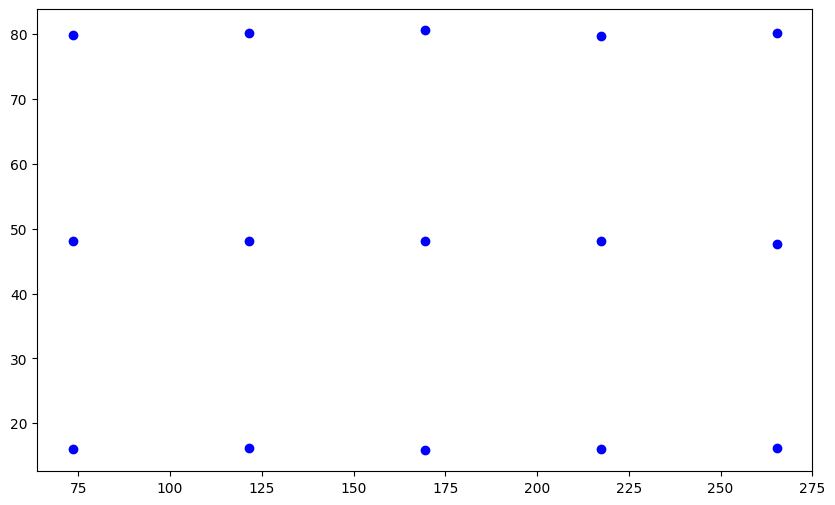

In [41]:
from scipy import ndimage

F_mag = np.mean(force_pad[:, :, :, 0], axis=0) ** 2 + np.mean(force_pad[:, :, :, 1], axis=0) ** 2                        # |F| in (y, x), evtl. über t gemittelt
mask = F_mag > 0.05 * F_mag.max()   # Schwellwert, z.B. ein paar Prozent
labels, n = ndimage.label(mask)    # n sollte 15 sein
centers = ndimage.center_of_mass(F_mag, labels, range(1, n + 1))
fig = plt.figure(figsize=(10, 6))
#plt.scatter([loc[1] for loc in turbine_locations], [loc[0] for loc in turbine_locations], color='red', label='Turbine Locations')
plt.scatter([c for r, c in centers], [r for r, c in centers], color='blue', label='Center of Mass')

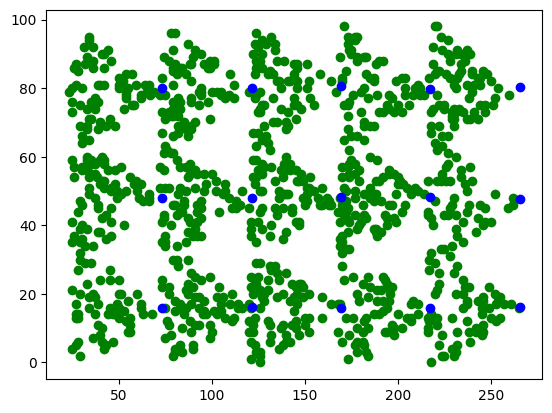

In [65]:
#sample kegelförmig vor center in anstromrichtung wie bei lidar
cone_angle = np.pi / 8  # Beispiel: 45 Grad Kegelwinkel
radius = 50  # Beispiel: Radius des Kegels
cone_mask = np.zeros_like(F_mag, dtype=bool)
for center in centers:
    center_y, center_x = int(center[0]), int(center[1])
    for y_f in range(F_mag.shape[0]):
        for x_f in range(F_mag.shape[1]):
            dy = center_y - y_f
            dx = center_x - x_f  # Invertiere dx, um die Richtung zu berücksichtigen
            distance = np.sqrt(dx**2 + dy**2)
            if distance <= radius and np.abs(np.arctan2(dy, dx)) <= cone_angle:
                cone_mask[y_f, x_f] = True
#sample data in cone
ys, xs = np.where(cone_mask)
idx = np.random.choice(len(xs), size=1000, replace=False)
# -> xs[idx], ys[idx]
x_data, y_data = xs[idx], ys[idx]
t_data = np.random.choice(np.arange(len(t)), size=100, replace=False)
plt.scatter(x_data, y_data, color='green', label='Sampled Data in Cone')
plt.scatter([c for r, c in centers], [r for r, c in centers], color='blue', label='Center of Mass')

Text(0.5, 1.0, 'Turbine Locations in Force Field')

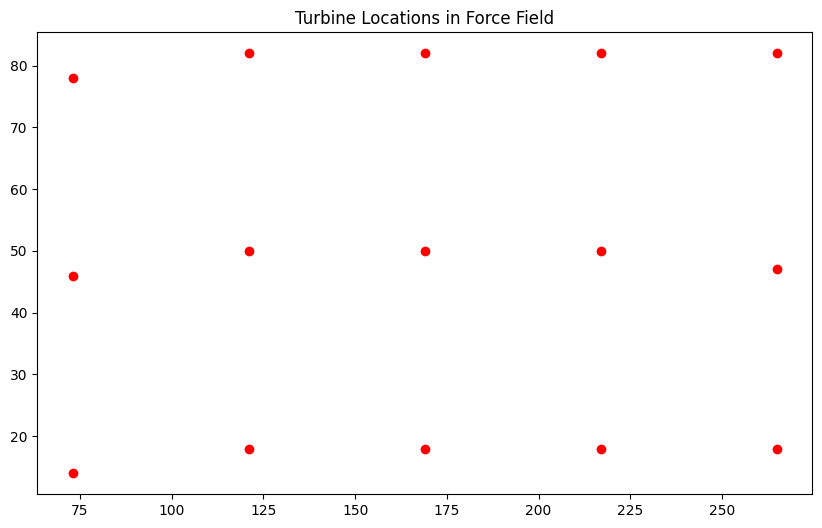

In [30]:
#scatter plot of the turbine locations
plt.figure(figsize=(10, 6))
plt.scatter([loc[1] for loc in turbine_locations], [loc[0] for loc in turbine_locations], color='red', label='Turbine Locations')
plt.title('Turbine Locations in Force Field')

In [15]:
np.argmin(force_x)

238447

In [ ]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path("..") / "data"
z_index = 18
train_n = 100
col_n = 100
device = "cpu"

# def get_wake_2d_data(data_dir: str, z_index: int, train_n: int, n_col: int, device: str):
# 1. HDF5 laden & bei z_index schneiden -> X, Y, u_true, v_true, p_true
# 2. Zufällige Indizes für train_batch ziehen (n_data Punkte für Data-Loss, n_col für PDE)
# 3. Gesamtes Gitter in val_batch packen
# 4. true_dict = {"u": u_true, "v": v_true, "p": p_true}


with h5py.File(DATA_DIR / "velocity_t0001.h5", "r") as data_file:
    field = np.asarray(data_file["velocity_0001"])
    x = np.asarray(data_file["xcoor"], dtype=np.float32)
    y = np.asarray(data_file["ycoor"], dtype=np.float32)
    z = np.asarray(data_file["zcoor"], dtype=np.float32)
    print(field.shape, x.shape, y.shape, z.shape)

(40, 100, 301, 3) (301,) (100,) (40,)


In [ ]:
snapshots, fields = [], []
prefix = "velocity"
for path in sorted(DATA_DIR.glob(f"{prefix}_t*.h5")):
    with h5py.File(path, "r") as f:
        for key in sorted(k for k in f if k.startswith(f"{prefix}_")):
            snapshots.append(int(key.split("_")[1]))  # velocity_0013 -> 13
            fields.append(f[key][18, :, :, :])  # nur die Ebene self.z_index
snapshots = np.array(snapshots)
fields = np.stack(fields)

In [ ]:
(snapshots - snapshots[0]) * 0.5

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19.])

In [ ]:
import h5py
import numpy as np
from pathlib import Path

DATA_DIR = Path("..") / "data"

Z = 17
DT = 0.5

AX_T, AX_Z, AX_Y, AX_X = 0, 1, 2, 3  # Achsenindizes für die Daten (time, z, y, x)


def load(prefix):
    snaps, fields = [], []
    for path in sorted(DATA_DIR.glob(f"{prefix}*.h5")):
        with h5py.File(path, "r") as f:
            for key in sorted(k for k in f if k.startswith(f"{prefix}_")):
                snaps.append(int(key.split("_")[1]))
                fields.append(f[key][Z - 2 : Z + 3])
    return np.array(snaps), np.stack(fields)


def d(f, coord, axis):
    """Berechnet die Ableitung der Funktion f an den Koordinaten coord entlang der Achse axis."""
    df = np.gradient(f, coord, axis=axis)
    return df


def rms(a):
    # rms nur über innere Punkte(am rand über  einseitife differenzen)
    return np.sqrt(np.mean(a[1:-1, 1:-1, 1:-1, 1:-1] ** 2))


snaps, vel = load("velocity")
_, pres = load("pressure")
_, force = load("force")
_, nu_t = load("sgsviscosity")


with h5py.File(DATA_DIR / "velocity_t0001.h5", "r") as f:
    x, y, z = (np.asarray(f[k], dtype=np.float64) for k in ("xcoor", "ycoor", "zcoor"))
z = z[Z - 2 : Z + 3]
t = (snaps - snaps[0]) * DT


# TODO: force auf das volle x-Gitter auffüllen (wie in data.py)
with h5py.File(DATA_DIR / "force_t0001.h5", "r") as f:
    x_force = np.asarray(f["xcoor"], dtype=np.float32)
    x_force_offset = len(x) - len(x_force)
force_pad = np.zeros_like(vel)
force_pad[:, :, :, x_force_offset:, :] = force

# TODO: u, v, w, p, f_x, f_y, nu als 4D-Arrays (t, z, y, x) herausziehen
u = vel[:, :, :, :, 0]
v = vel[:, :, :, :, 1]
w = vel[:, :, :, :, 2]
p = pres.squeeze()
f_x = force_pad[:, :, :, :, 0]
f_y = force_pad[:, :, :, :, 1]
nu = nu_t.squeeze()


# --- 2. Ableitungen ---
# TODO: u_t, u_x, u_y, u_z, u_xx, u_yy, u_zz, dasselbe für v
# TODO: w_x, w_z, p_x, p_y, nu_x, nu_y, nu_z


u_x = d(u, x, AX_X)
u_y = d(u, y, AX_Y)
u_z = d(u, z, AX_Z)
u_t = d(u, t, AX_T)
u_xx = d(u_x, x, AX_X)
u_yy = d(u_y, y, AX_Y)
u_zz = d(u_z, z, AX_Z)
v_x = d(v, x, AX_X)
v_y = d(v, y, AX_Y)
v_z = d(v, z, AX_Z)
v_t = d(v, t, AX_T)
v_xx = d(v_x, x, AX_X)
v_yy = d(v_y, y, AX_Y)
v_zz = d(v_z, z, AX_Z)
w_x = d(w, x, AX_X)
w_z = d(w, z, AX_Z)
p_x = d(p, x, AX_X)
p_y = d(p, y, AX_Y)
nu_x = d(nu, x, AX_X)
nu_y = d(nu, y, AX_Y)
nu_z = d(nu, z, AX_Z)

# --- 3. Terme der x-Impulsgleichung einzeln ("Term-Budget") ---
terms_x = {
    "u_t": u_t,
    "konvektion": u * u_x + v * u_y,  # u*u_x + v*u_y
    "p_x": p_x,
    "f_x": f_x,
    "nu*lap2d": nu * (u_xx + u_yy),  # nu*(u_xx + u_yy)
    "nu-gradient": 2 * nu_x * u_x + nu_y * (u_y + v_x),  # 2*nu_x*u_x + nu_y*(u_y + v_x)
    "w*u_z": w * u_z,  # w*u_z
    "z-viskos": nu * u_zz + nu_z * (u_z + w_x),  # nu*u_zz + nu_z*(u_z + w_x)
}

for name, val in terms_x.items():
    print(f"{name:>12}: {rms(val):.3e}")

# --- 4. Residuen der vier Varianten, relativ zur Konvektion ---
ref = rms(terms_x["konvektion"])
R1 = terms_x["u_t"] + terms_x["konvektion"] + terms_x["p_x"] - terms_x["f_x"]  # nu = 0
R2 = (
    terms_x["u_t"]
    + terms_x["konvektion"]
    + terms_x["p_x"]
    - terms_x["f_x"]
    - nu.mean() * (u_xx + u_yy)
)  # nu = konstant (z.B. nu.mean())
R3 = (
    terms_x["u_t"]
    + terms_x["konvektion"]
    + w * u_z
    + terms_x["p_x"]
    - terms_x["f_x"]
    - terms_x["nu*lap2d"]
    - terms_x["nu-gradient"]
)  # nu = nu_t(x,y,t) inkl. Gradiententerm
R4 = (
    terms_x["u_t"]
    + terms_x["konvektion"]
    + terms_x["p_x"]
    - terms_x["f_x"]
    - terms_x["nu*lap2d"]
    - terms_x["nu-gradient"]
    - terms_x["z-viskos"]
)  # R3 + z-Terme
for name, R in [("nu=0", R1), ("nu=konst", R2), ("nu_t", R3), ("nu_t+3D", R4)]:
    print(f"{name:>10}: {rms(R) / ref:.3f}")

    # --- 5. Kontinuität ---
# TODO: rms(u_x + v_y) und rms(u_x + v_y + w_z), jeweils relativ zu rms(u_x)
ref = rms(u_x)
R1 = u_x + v_y
R2 = u_x + v_y + w_z
for name, R in [("2D", R1), ("3D", R2)]:
    print(f"{name:>10}: {rms(R) / ref:.3f}")

         u_t: 2.585e-01
  konvektion: 2.205e-01
         p_x: 5.846e-02
         f_x: 9.062e-02
    nu*lap2d: 1.189e-03
 nu-gradient: 9.648e-04
       w*u_z: 5.709e-02
    z-viskos: 4.500e-03
      nu=0: 0.538
  nu=konst: 0.538
      nu_t: 0.508
   nu_t+3D: 0.537
        2D: 1.092
        3D: 0.590


nu_t lohnt nicht, 2d schnitt ist größter hebel, weil kontinuität nicht gilt, vielleicht niedrig gewichten

In [ ]:
res_mom_x = (
    u_t + u * u_x + v * u_y + p_x - (nu + nu_t) * (u_xx + u_yy) - f_x
)  # rho bei kraft und pressure wahrscheinlich schon eingerechten, prüfen!
res_mom_y = (
    v_t + u * v_x + v * v_y + p_y - (nu + nu_t) * (v_xx + v_yy) - f_y
)  # hier ist nu_t keine konstante mehr, darf also eigentlich nicht rausgezogen werden
res_cont = u_x + v_y